🟢 المرحلة 2: تدريب نموذج Image Classification

In [3]:


import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

1️⃣ Device

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


2️⃣ Dataset Path

In [5]:
DATASET_DIR = r"C:\Users\hp\Desktop\CV\Fruit_Vision_Project\dataset"

3️⃣ Image Transforms

In [6]:
train_transforms = transforms.Compose([
transforms.Resize((224, 224)),
transforms.RandomHorizontalFlip(),
transforms.ToTensor(),
transforms.Normalize(
mean=[0.485, 0.456, 0.406],
std=[0.229, 0.224, 0.225]
)
])

val_transforms = transforms.Compose([
transforms.Resize((224, 224)),
transforms.ToTensor(),
transforms.Normalize(
mean=[0.485, 0.456, 0.406],
std=[0.229, 0.224, 0.225]
)
])

4️⃣ Load Dataset

In [7]:
train_dataset = datasets.ImageFolder(
root=os.path.join(DATASET_DIR, "train"),
transform=train_transforms
)

val_dataset = datasets.ImageFolder(
root=os.path.join(DATASET_DIR, "val"),
transform=val_transforms
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

class_names = train_dataset.classes
print("Classes:", class_names)

Classes: ['fresh', 'rotten']


5️⃣ Model: ResNet18

In [13]:
# تحميل النموذج
model = models.resnet18(pretrained=True)

# تجميد الطبقات
for param in model.parameters():
    param.requires_grad = False

# تعديل آخر طبقة (2 أصناف)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

model = model.to(device)

print("OK - Model ready")


OK - Model ready


6️⃣ Loss & Optimizer

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

7️⃣ Training Loop

In [16]:
EPOCHS = 5

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print("-" * 30)

# ---- Training ----
model.train()
correct, total = 0, 0

for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    _, preds = torch.max(outputs, 1)
    correct += (preds == labels).sum().item()
    total += labels.size(0)

train_acc = correct / total

# ---- Validation ----
model.eval()
correct, total = 0, 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

val_acc = correct / total

print(f"Train Accuracy: {train_acc:.2f}")
print(f"Val Accuracy:   {val_acc:.2f}")


Epoch 1/5
------------------------------

Epoch 2/5
------------------------------

Epoch 3/5
------------------------------

Epoch 4/5
------------------------------

Epoch 5/5
------------------------------
Train Accuracy: 0.93
Val Accuracy:   0.97


8️⃣ Save Model

In [ ]:
os.makedirs("../models", exist_ok=True)
MODEL_PATH = "../models/classification_model.pth"
torch.save(model.state_dict(), MODEL_PATH)
print("\n✅ Training finished successfully")
print(f"✅ Model saved at: {MODEL_PATH}")


✅ Training finished successfully
✅ Model saved at: ../models/classification_model.pth


9️⃣ المرحلة 3: اختبار النموذج (Inference & Evaluation)

Using device: cpu
✅ Model loaded successfully


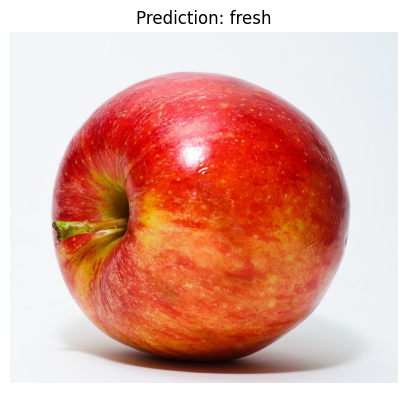

🍎 Prediction: fresh


In [61]:
%matplotlib inline
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import os

# =========================
# 1️⃣ إعداد الجهاز
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =========================
# 2️⃣ Classes
# =========================
class_names = ['fresh', 'rotten']

# =========================
# 3️⃣ Transform (نفس التدريب)
# =========================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# =========================
# 4️⃣ Load Model
# =========================
model = models.resnet18(pretrained=False)
model.fc = nn.Linear(model.fc.in_features, 2)

MODEL_PATH = r"C:\Users\hp\Desktop\CV\models\classification_model.pth"
state_dict = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()
print("✅ Model loaded successfully")

# =========================
# 5️⃣ دالة التنبؤ
# =========================
def predict_image(image_path):
    img = Image.open(image_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(input_tensor)
        _, predicted = torch.max(output, 1)
    return class_names[predicted.item()], img

# =========================
# 6️⃣ تجربة صورة واحدة
# =========================
image_path = r"C:\Users\hp\Desktop\CV\apple copy 2.png"  # غيّر الصورة
pred, img = predict_image(image_path)

# عرض الصورة مع النتيجة
plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title(f"Prediction: {pred}")
plt.axis("off")
plt.show()

# طباعة النتيجة في console
print(f"🍎 Prediction: {pred}")


🟢 المرحلة 3: تدريب نموذج Object Detection (YOLO)

### 1️⃣ تحميل نموذج الكشف المُدرّب (YOLOv5)
تحميل الأوزان الخاصة بنموذج YOLOv5 باستخدام `torch.hub` المحلي.

In [ ]:
import os
import torch
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = os.getcwd()
YOLO_DIR = os.path.join(BASE_DIR, 'yolov5')
WEIGHTS_PATH = os.path.join(YOLO_DIR, 'runs', 'train', 'exp', 'weights', 'best.pt')
if not os.path.exists(WEIGHTS_PATH):
    WEIGHTS_PATH = os.path.join(YOLO_DIR, 'runs', 'train', 'fruit_detector', 'weights', 'best.pt')

print('📁 مسار الأوزان:', WEIGHTS_PATH)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

yolo_model = torch.hub.load(YOLO_DIR, 'custom', path=WEIGHTS_PATH, source='local')
yolo_model.to(device)
yolo_model.eval()
print('✅ تم تحميل نموذج YOLOv5 بنجاح على الجهاز:', device)


### 2️⃣ اختبار كشف الأجسام ورسم صناديق التحديد (Bounding Boxes)
تجربة فحص صورة واستخراج الفئات ومواقع الصناديق ونسب الثقة.

In [ ]:
test_image_path = os.path.join(BASE_DIR, '..', 'apple.png')
if not os.path.exists(test_image_path):
    fresh_apples_dir = os.path.join(BASE_DIR, 'dataset', 'test', 'freshapples')
    if os.path.exists(fresh_apples_dir) and os.listdir(fresh_apples_dir):
        test_image_path = os.path.join(fresh_apples_dir, os.listdir(fresh_apples_dir)[0])

print('🔍 فحص الصورة:', test_image_path)
results = yolo_model(test_image_path)

df = results.pandas().xyxy[0]
print('\n📋 نتائج الكشف (Detections):')
print(df[['name', 'confidence', 'xmin', 'ymin', 'xmax', 'ymax']])

%matplotlib inline
plt.figure(figsize=(10, 8))
plt.imshow(np.squeeze(results.render()))
plt.axis('off')
plt.title('YOLOv5 Fruit Detection Results', fontsize=14)
plt.show()


### 3️⃣ دمج النظام: كشف وتصنيف (Full Pipeline)
فحص شامل يجمع بين تصنيف جودة الفاكهة (ResNet18) وكشفها الموضعي (YOLOv5).

In [ ]:
def inspect_fruit_pipeline(image_path):
    img = Image.open(image_path).convert('RGB')
    pred_quality, _ = predict_image(image_path)
    detection_res = yolo_model(image_path)
    detections_df = detection_res.pandas().xyxy[0]
    
    print('=' * 50)
    print('🍏 تقرير الفحص الشامل للصورة:', os.path.basename(image_path))
    print('🔬 جودة الفاكهة العامة (ResNet18):', pred_quality.upper())
    print('🎯 عدد الأجسام المكتشفة (YOLOv5):', len(detections_df))
    for idx, row in detections_df.iterrows():
        print(f"   • الصنف: {row['name']} | نسبة الثقة: {row['confidence']*100:.1f}%")
    print('=' * 50)
    
    plt.figure(figsize=(8, 6))
    plt.imshow(np.squeeze(detection_res.render()))
    plt.title(f'Inspection: {pred_quality.upper()}', fontsize=14, color='green' if pred_quality == 'fresh' else 'red')
    plt.axis('off')
    plt.show()

inspect_fruit_pipeline(test_image_path)
